<a href="https://colab.research.google.com/github/nkordylewicz/ML-for-space-applications/blob/main/Lab4_ANN_intro_diode_AKM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##### Copyright 2018 The TensorFlow Authors.

In [1]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# An introduction to ANN

PS: Some of this has been inspired by the recent Udacity course: https://classroom.udacity.com/courses/ud187.

#Diode Equation (assume you are Shockley)

Lets think of the way  William Shockley might have found the diode equation. All he had with him were some measurements of $I_D$ given values for $V_D$.

We already know that the equation that he found to be the the best is $I_D = I_O (e^{V_D/V_T} - 1)$.

Lets assume that we have the following readings of $V_D$ = (0, 0.2, 0.4, 0.6, 0.7) .

Lets cheat and find the values for $I_D$. Assume that we have got these current values from complicated lab-based experiments. We are asked to act Shockly and find a model which can churn out values of $I_D$ given any value of $V_D$.

In [2]:
import matplotlib as mp
import numpy as np

I_o = 3.2e-12
v_d = np.array([0,0.1, 0.2,0.22, 0.3, 0.35, 0.4,0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8],  dtype=float)
i_d = I_o*(np.exp(v_d/0.025) - 1)
print(i_d)


[0.00000000e+00 1.71514080e-10 9.53586556e-09 2.12263808e-08
 5.20812133e-07 3.84833051e-06 2.84355505e-05 2.10111898e-04
 1.55252862e-03 1.14717211e-02 8.47651908e-02 6.26334750e-01
 4.62802261e+00 3.41967187e+01 2.52681473e+02]


<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/tensorflow/examples/courses/udacity_intro_to_tensorflow_for_deep_learning/l02c01_celsius_to_fahrenheit.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/tensorflow/examples/courses/udacity_intro_to_tensorflow_for_deep_learning/l02c01_celsius_to_fahrenheit.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View source on GitHub</a>
  </td>
</table>

The first step in any machine learning activitiy is to check how does the data "look" like!  

Dont forget that a lot of our intuitive gut feeling is based around vision. (We will talk more about this later.) This is exactly why methods like principal component analysis are extremely powerful.

So lets plot it.

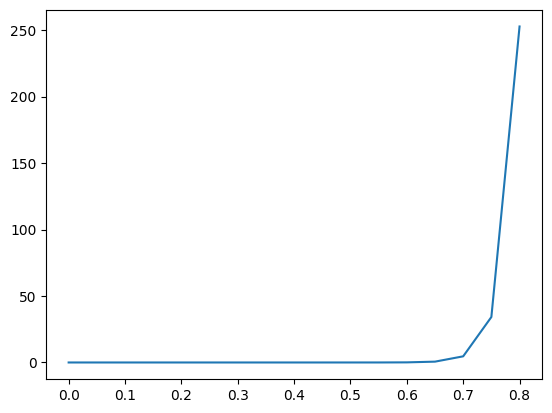

In [3]:
mp.pyplot.plot(v_d,i_d)

So from the plot what do you think the equation might be? Maybe its quadratic? Maybe its exponential. So if its exponential then it will look like $I_D = x (e^{yV_D} + p)$. So to get this trick to work we need to find these three **parameters**  and thats why such methods are called .....guess.....**parametric methods** (we will discuss more about this later!)

How would you find these parameters? What are the possible issues and benefits of this method?

Now lets jump to the other type of trick where we do not impose any "model" on the data. Rather, we expect the data to lead our way!

**In God we trust, rest others bring data!**...late Edwards Deming (father of lean startup)

Lets build a Neural Network to model this. I.e. it should be able to predict the current given the voltage.

## Import dependencies

First, import TensorFlow. Here, we're calling it `tf` for ease of use. We also tell it to only display errors.



In [4]:
from __future__ import absolute_import, division, print_function
import tensorflow as tf

import numpy as np

## Set up training data

As we saw before, supervised Machine Learning is all about figuring out an algorithm, given a set of inputs and outputs. Since the task here is to create a model that can give diode current from the voltage, we shall use $I_0$ as the output and $V_D$ as the input.

### Some Machine Learning terminology

 - **Feature** — The input(s) to our model. In this case, a single value — the diode voltage in V.

 - **Labels** — The output our model predicts. In this case, a single value — the diode current in A.

 - **Example** — A pair of inputs/outputs used during training. In our case a pair of values from `V_D` and `I_D` at a specific index.


## Create the model

Next create the model. We will use a very simple model, a Dense network. Since the problem is straightforward, this network will require only a single layer, with a single neuron.

### Build a layer

We'll call the layer `l0` and create it by instantiating `tf.keras.layers.Dense` with the following configuration:

*   `input_shape=[1]` — This specifies that the input to this layer is a single value. That is, the shape is a one-dimensional array with one member. Since this is the first (and only) layer, that input shape is the input shape of the entire model. The single value is a floating point number, representing diode voltage.

*   `units=1` — This specifies the number of neurons in the layer. The number of neurons defines how many internal variables the layer has to try to learn how to solve the problem. Since this is the final layer, it is also the size of the model's output — a single float value representing diode current. (In a multi-layered network, the size and shape of the later would need to match the `input_shape` of the next layer.)


In [5]:
l0 = tf.keras.layers.Dense(units=1, input_shape=[1])
#l0 = tf.keras.layers.Dense(units=100, activation='tanh', input_shape=[1])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Assemble layers into the model

Once layers are defined, they need to be assembled into a model. The **Sequential model** definition takes a list of layers as argument, specifying the calculation order from the input to the output.

This model has just a single layer, l0.

In [6]:
model = tf.keras.Sequential([l0])

**Note**

You will often see the layers defined inside the model definition, rather than beforehand:

```python
model = tf.keras.Sequential([
  tf.keras.layers.Dense(units=1, input_shape=[1])
])
```

## Compile the model, with loss and optimizer functions

Before training, the model has to be compiled. When compiled for training, the model is given:

- **Loss function** — A way of measuring how far off predictions are from the desired outcome. (The measured difference is called the "loss".) REF: https://keras.io/losses/

- **Optimizer function** — A way of adjusting internal values in order to reduce the loss. REF: https://keras.io/optimizers/


In [7]:
model.compile(loss='mean_squared_error',
              optimizer=tf.keras.optimizers.Adam(0.1))

These are used during training (`model.fit()`, below) to first calculate the loss at each point, and then improve it. In fact, the act of calculating the current loss of a model and then improving it is precisely what training is.

During training, the optimizer function is used to calculate adjustments to the model's internal variables. The goal is to adjust the internal variables until the model (which is really a math function) mirrors the actual equation for converting $v_D$ to $I_D$.

TensorFlow uses numerical analysis to perform this tuning, and all this complexity is hidden from you so we will not go into the details here. What is useful to know about these parameters are:



One part of the Optimizer you may need to think about when building your own models is the learnign rate (`0.1` in the code above). This is the step size taken when adjusting values in the model. If the value is too small, it will take too many iterations to train the model. Too large, and accuracy goes down. Finding a good value often involves some trial and error, but the range is usually within 0.001 (default), and 0.1.

https://keras.io/models/sequential/

## Train the model

Train the model by calling the `fit` method.

During training, the model takes in v_d values, performs a calculation using the current internal variables (called "weights") and outputs values which are meant to be the i_d values. Since the weights are intially set randomly, the output will not be close to the correct value. The difference between the actual output and the desired output is calculated using the loss function, and the optimizer function directs how the weights should be adjusted.

This cycle of calculate, compare, adjust is controlled by the `fit` method. The first argument is the inputs, the second argument is the desired outputs. The `epochs` argument specifies how many times this cycle should be run, and the `verbose` argument controls how much output the method produces.

In [8]:
history = model.fit(v_d, i_d, epochs=5000, verbose=False)
print("Finished training the model")

Finished training the model


## Display training statistics

The `fit` method returns a history object. We can use this object to plot how the loss of our model goes down after each training epoch.

We'll use [Matplotlib](https://matplotlib.org/) to visualize this (you could use another tool). As you can see, our model improves very quickly at first, and then has a steady, slow improvement until it is very near "perfect" towards the end.



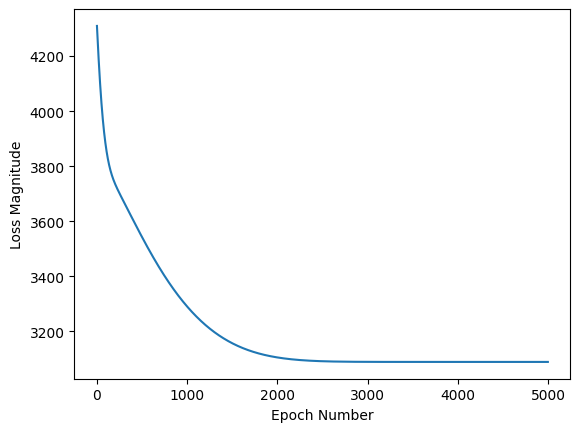

In [9]:
import matplotlib.pyplot as plt
plt.xlabel('Epoch Number')
plt.ylabel("Loss Magnitude")
plt.plot(history.history['loss'])

## Use the model to predict values

Now you have a model that has been trained to learn the relationshop between `v_d` and `i_d`. You can use the predict method to have it calculate the diode current. But unfortunately the error it converges to seems pretty bad. Lets try to use it anyway.

So, for example, if the diode voltage is 0.72 V then we expect a diode current of 10.3A. Lets see what we get.

In [10]:
print(model.predict(np.array([[0.72]])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
[[54.9359]]


##Post-mortem

Is this good? Hmmmmmmmm. Lets run another time.....But the error seems to be pretty high. What can we do now?

Mark that the model we used is linear. And we are trying to learn something which is exponential! Can we not add some nonlinearlity into the model? Try by adding a nonlinear activation function in the model and see what happens.

The error seems to be going down. Should we increase the number of epochs? Lets try that as well.






## Looking at the layer weights

Finally, let's print the internal variables of the Dense layer.

In [11]:
print("These are the layer variables: {}".format(l0.get_weights()))

These are the layer variables: [array([[125.72289]], dtype=float32), array([-35.584583], dtype=float32)]


### Some more experiments

Something is not going well. What can we do? Can we add more layers?

Universal approximation theorem.
A single hidden layer can approximate any function!

Finished training the model
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
[[5.1806207]]


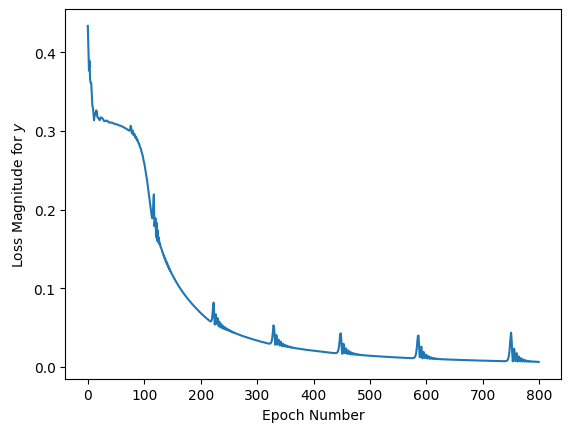

In [12]:
l0 = tf.keras.layers.Dense(units=850, activation='tanh',input_shape=[1])
l1 = tf.keras.layers.Dense(units=1)
model = tf.keras.Sequential([l0, l1])
model.compile(loss='mean_squared_error', optimizer=tf.keras.optimizers.Adam(0.1))
history = model.fit(v_d, i_d, epochs=800, verbose=False)
print("Finished training the model")
print(model.predict(np.array([[0.72]])))
#print("Model predicts that 100 degrees Celsius is: {} degrees Fahrenheit".format(model.predict([0.72])))
#print("These are the l0 variables: {}".format(l0.get_weights()))
#print("These are the l1 variables: {}".format(l1.get_weights()))
#print("These are the l2 variables: {}".format(l2.get_weights()))
ppp = history.history['loss']
qqq = np.multiply(ppp,0.0001)
plt.xlabel('Epoch Number')
plt.ylabel("Loss Magnitude for $y$")
plt.plot(qqq)

##Play-around

We still did not get anything decent. But the theory says it should work. Try increasing the number of nodes in the hidden layer and see what happens.

So which is better? Parametric or data-centered ANN approach?

What else did you learn from this?

Answer: The parametric approach is better here: the physics gives the form $I_D = I_0(e^{V_D/V_T}-1)$, so only 2–3 parameters have to be fitted and the model extrapolates correctly. The ANN has hundreds of parameters, only 15 data points and no physical prior — it fits slowly, depends on the learning rate and random initialisation, and is unreliable outside the training range. The ANN approach is useful when the functional form is unknown and a lot of data is available.

# Lab: ANN classification of Sentinel-2 patches (Task 1)

The notebook uses an ANN for regression ($V_D \to I_D$). Here the Keras building blocks are used for classification
of 200×200-pixel Sentinel-2 patches into urban or forest.

**Data sources:**
- Sentinel-2 L2A surface reflectance (`COPERNICUS/S2_SR_HARMONIZED`), cloud-masked median composite
- ESA WorldCover 10 m 2021 (`ESA/WorldCover/v200`) — used to create the training labels.

**Area:**
- Kraków and the Upper Silesian conurbation with the surrounding forests;
- Warsaw and Kampinos Forest for a check on new patches.

## 0. Setup


In [13]:
import warnings, time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from concurrent.futures import ThreadPoolExecutor
from pyproj import Transformer

print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


In [14]:
import ee
PROJECT = 'commanding-air-494108-v2'
ee.Authenticate()
ee.Initialize(project=PROJECT)

## 1. Posing the task as a function

A Sentinel-2 patch of 200×200 pixels with $B$ spectral bands is a point in $\mathbb{R}^{200\times200\times B}$.
We look for a function

$$
f:\ \mathbb{R}^{200\times200\times B} \rightarrow \{0, 1\}, \qquad 0 = \text{forest},\ 1 = \text{urban}
$$

In practice the network learns the *probability* of the class,
$\hat{p} = f_\theta(\mathbf{x}) = P(\text{urban}\mid\mathbf{x}) \in [0,1]$, and the tag is $\hat{y} = [\hat{p} > 0.5]$.
The parameters $\theta$ (weights and biases) are found by minimising the binary cross-entropy between $\hat{p}$ and the true tags,
in the same way as the mean squared error was minimised for $I_D(V_D)$ in the diode example.

Feeding all $200\cdot200\cdot5 = 200\,000$ pixel values directly into a dense network would give 200 000 weights
per neuron with only a few hundred training examples, so the patch is first reduced to a compact feature vector:

- **Variant A – spectral statistics (14 features):** mean and standard deviation of B2, B3, B4, B8, B11 and of the NDVI and NDBI indices;
- **Variant B – downsampled pixels (2000 features):** the patch averaged in 10×10 blocks → 20×20×5 values, flattened.

## 2. Creating the training data

### 2.1 Sentinel-2 composite and label source

In [15]:
AOI = ee.Geometry.Rectangle([18.6, 49.75, 20.45, 50.45])
BANDS = ['B2', 'B3', 'B4', 'B8', 'B11']
PATCH = 200
RES = 10

def mask_s2(img):
    scl = img.select('SCL')
    ok = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return img.updateMask(ok)

s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
        .filterDate('2023-06-01', '2023-08-31')
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
        .map(mask_s2)
        .select(BANDS)
        .median())

worldcover = ee.Image('ESA/WorldCover/v200/2021').select('Map')
stack = s2.toUint16().addBands(worldcover.toUint16())
print(stack.bandNames().getInfo())

['B2', 'B3', 'B4', 'B8', 'B11', 'Map']


### 2.2 Candidate patch centres

Random points are drawn separately inside built-up (WorldCover 50) and tree-cover (WorldCover 10) pixels.
Points closer than 2 km to each other are removed, so the 2×2 km patches do not overlap.

In [16]:
N_CANDIDATES = 1500

cls_img = worldcover.remap([10, 50], [0, 1]).rename('cls')
pts = cls_img.stratifiedSample(numPoints=N_CANDIDATES, classBand='cls', region=AOI,
                               scale=100, seed=42, geometries=True, tileScale=4)
feats = pts.getInfo()['features']
lonlat = np.array([f['geometry']['coordinates'] for f in feats])
print('Candidate points:', len(lonlat))

to_utm = Transformer.from_crs('EPSG:4326', 'EPSG:32634', always_xy=True)
xs, ys = to_utm.transform(lonlat[:, 0], lonlat[:, 1])
centres = np.c_[xs, ys]

rng = np.random.default_rng(0)
keep = []
for i in rng.permutation(len(centres)):
    if all(np.max(np.abs(centres[i] - centres[j])) >= PATCH * RES for j in keep):
        keep.append(i)
centres = centres[keep]
print('Non-overlapping centres:', len(centres))

Candidate points: 3000
Non-overlapping centres: 832


### 2.3 Downloading the 200×200 patches and assigning the tags

An array is downloaded for each centre, and the tag is derived inside the patch:

- **urban (1)** if ≥ 40 % of pixels are built-up, I had to change the limit to be lower, because classes vere really uneaven,
- **forest (0)** if ≥ 80 % of pixels are tree cover,
- otherwise the patch is mixed and discarded.

In [17]:
def get_patch(cx, cy, crs='EPSG:32634', retries=3):
    req = {
        'expression': stack,
        'fileFormat': 'NUMPY_NDARRAY',
        'grid': {
            'dimensions': {'width': PATCH, 'height': PATCH},
            'affineTransform': {'scaleX': RES, 'shearX': 0, 'translateX': cx - PATCH * RES / 2,
                                'shearY': 0, 'scaleY': -RES, 'translateY': cy + PATCH * RES / 2},
            'crsCode': crs,
        },
    }
    for k in range(retries):
        try:
            arr = ee.data.computePixels(req)
            spec = np.stack([arr[b] for b in BANDS], axis=-1)
            lc = arr['Map']
            return spec, np.mean(lc == 50), np.mean(lc == 10)
        except Exception as e:
            time.sleep(2 * (k + 1))
    return None

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    results = list(ex.map(lambda c: get_patch(*c), centres))
print(f'Downloaded in {time.time() - t0:.0f} s')

patches, labels, centres_ok = [], [], []
for c, r in zip(centres, results):
    if r is None:
        continue
    spec, built, tree = r
    if np.any(spec.sum(-1) == 0):
        continue
    if built >= 0.4:
        patches.append(spec); labels.append(1); centres_ok.append(c)
    elif tree >= 0.8:
        patches.append(spec); labels.append(0); centres_ok.append(c)

patches = np.array(patches, dtype=np.uint16)
labels = np.array(labels, dtype=np.float32)
centres_ok = np.array(centres_ok)
print('Patches:', patches.shape, '| urban:', int(labels.sum()), '| forest:', int((labels == 0).sum()))

# forest patches were subsampled to balance the classes
rng = np.random.default_rng(0)
i_u = np.where(labels == 1)[0]
i_f = np.where(labels == 0)[0]
i_f = rng.choice(i_f, size=min(len(i_f), len(i_u)), replace=False)
keep = np.sort(np.r_[i_u, i_f])
patches, labels, centres_ok = patches[keep], labels[keep], centres_ok[keep]
print('Balanced:', patches.shape, '| urban:', int(labels.sum()), '| forest:', int((labels == 0).sum()))

np.savez_compressed('/content/s2_patches.npz', patches=patches, labels=labels, centres=centres_ok)

Downloaded in 140 s
Patches: (161, 200, 200, 5) | urban: 56 | forest: 105
Balanced: (112, 200, 200, 5) | urban: 56 | forest: 56


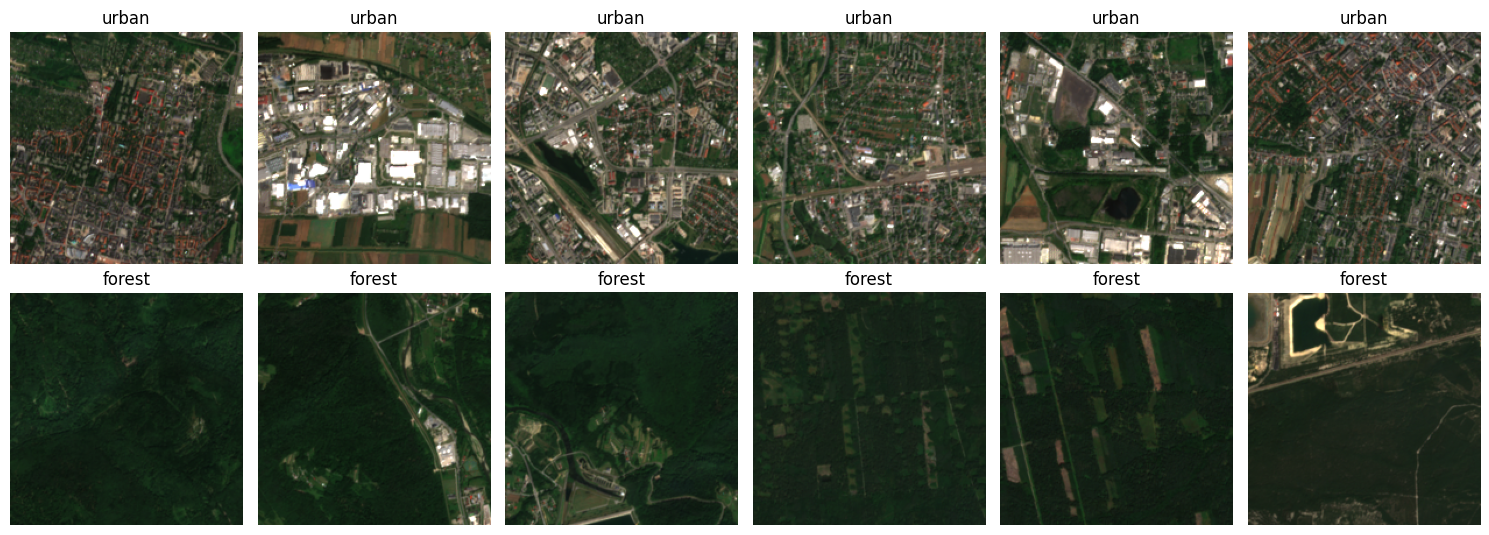

In [18]:
def rgb(p):
    img = p[..., [2, 1, 0]].astype(float) / 10000 * 3.5
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for row, cls, name in [(0, 1, 'urban'), (1, 0, 'forest')]:
    idx = np.where(labels == cls)[0][:6]
    for ax, i in zip(axes[row], idx):
        ax.imshow(rgb(patches[i])); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

### 2.4 Feature vectors and train/test split

In [19]:
def features_stats(P):
    # variant A
    R = P.astype(np.float32) / 10000.0   # reflectance
    b2, b3, b4, b8, b11 = [R[..., i] for i in range(5)]
    ndvi = (b8 - b4) / (b8 + b4 + 1e-6)
    ndbi = (b11 - b8) / (b11 + b8 + 1e-6)
    layers = [b2, b3, b4, b8, b11, ndvi, ndbi]
    return np.stack([f(l, axis=(1, 2)) for l in layers for f in (np.mean, np.std)], axis=1)

def features_pixels(P, block=10):
    # variant B
    R = P.astype(np.float32) / 10000.0
    n, h, w, c = R.shape
    R = R.reshape(n, h // block, block, w // block, block, c).mean(axis=(2, 4))
    return R.reshape(n, -1)

X_stats = features_stats(patches)
X_pix = features_pixels(patches)
print('Variant A:', X_stats.shape, '| Variant B:', X_pix.shape)

idx_train, idx_test = train_test_split(np.arange(len(labels)), test_size=0.2,
                                       stratify=labels, random_state=42)
y_train, y_test = labels[idx_train], labels[idx_test]

def standardise(X):
    mu, sd = X[idx_train].mean(0), X[idx_train].std(0) + 1e-6     # statistics from the training set only
    return (X[idx_train] - mu) / sd, (X[idx_test] - mu) / sd, (mu, sd)

XA_train, XA_test, scaler_A = standardise(X_stats)
XB_train, XB_test, scaler_B = standardise(X_pix)
print('Train:', len(y_train), '| Test:', len(y_test))

Variant A: (112, 14) | Variant B: (112, 2000)
Train: 89 | Test: 23


## 3. The bare-bones ANN architecture

The problem may be resolved by classification counterpart of the single-neuron
model.

- input: 14 features (Variant A), output: 1 neuron (P(urban)),
- 15 trainable parameters (14 weights + 1 bias),
- loss: `binary_crossentropy`, optimiser: Adam.

Urban and forest differ strongly in NDVI
and in the NIR/SWIR bands, so this model should work well. Nonlinearity is added later by a hidden layer.

In [20]:
tf.keras.utils.set_random_seed(0)

l0 = tf.keras.layers.Dense(units=1, activation='sigmoid', input_shape=[XA_train.shape[1]])
model = tf.keras.Sequential([l0])
model.compile(loss='binary_crossentropy',
              optimizer=tf.keras.optimizers.Adam(0.01),
              metrics=['accuracy'])

history = model.fit(XA_train, y_train, epochs=200, validation_split=0.2, verbose=False)
print("Finished training the model")

Finished training the model


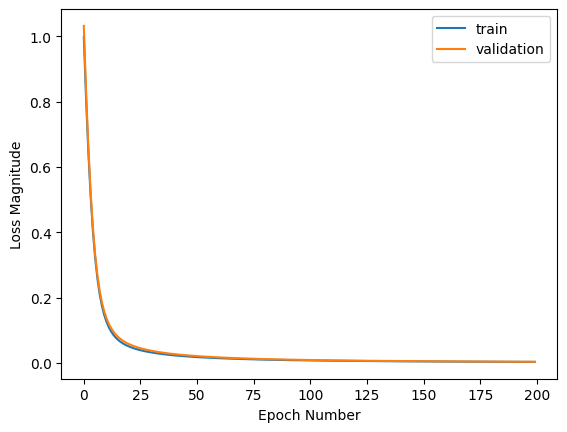

Test loss: 0.059 | Test accuracy: 0.957


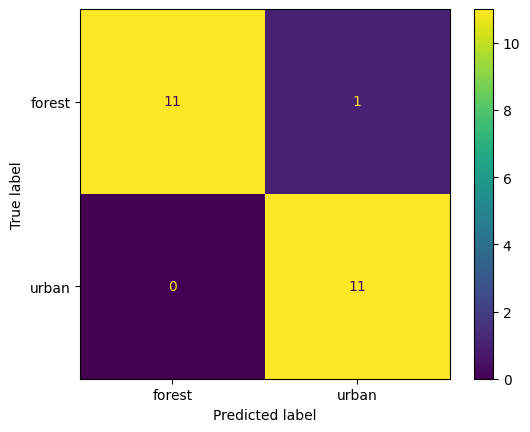

In [21]:
plt.xlabel('Epoch Number'); plt.ylabel('Loss Magnitude')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.legend(); plt.show()

test_loss, test_acc = model.evaluate(XA_test, y_test, verbose=False)
print(f'Test loss: {test_loss:.3f} | Test accuracy: {test_acc:.3f}')

y_pred = (model.predict(XA_test, verbose=False).ravel() > 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['forest', 'urban']).plot()
plt.show()

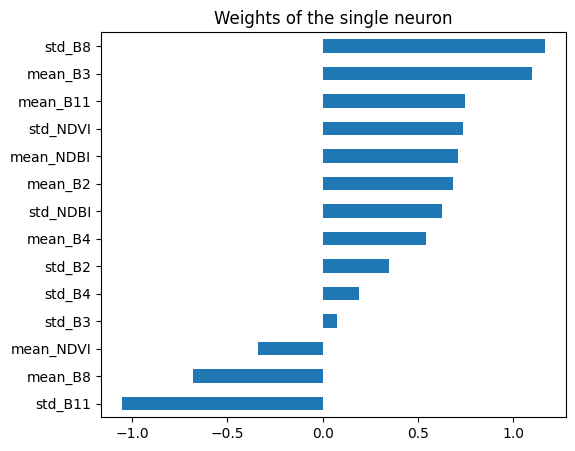

In [22]:
# weights on standardised features
names = [f'{s}_{l}' for l in ['B2', 'B3', 'B4', 'B8', 'B11', 'NDVI', 'NDBI'] for s in ('mean', 'std')]
w, b = l0.get_weights()
pd.Series(w.ravel(), index=names).sort_values().plot.barh(figsize=(6, 5), title='Weights of the single neuron')
plt.show()

## 4–5. Experiments: changing the architecture

Each configuration is trained **3 times with different random seeds** (the initial weights are random). Mean ± std of the test accuracy is reported.

In [23]:
def build(n_inputs, hidden=(), activation='relu'):
    layers = []
    for k, units in enumerate(hidden):
        if k == 0:
            layers.append(tf.keras.layers.Dense(units=units, activation=activation, input_shape=[n_inputs]))
        else:
            layers.append(tf.keras.layers.Dense(units=units, activation=activation))
    if hidden:
        layers.append(tf.keras.layers.Dense(units=1, activation='sigmoid'))
    else:
        layers.append(tf.keras.layers.Dense(units=1, activation='sigmoid', input_shape=[n_inputs]))
    return tf.keras.Sequential(layers)

def run(name, X_tr, X_te, hidden=(), activation='relu', optimizer='adam', lr=0.01,
        epochs=200, seeds=(0, 1, 2)):
    accs, losses, histories = [], [], []
    t0 = time.time()
    for s in seeds:
        tf.keras.utils.set_random_seed(s)
        model = build(X_tr.shape[1], hidden, activation)
        opt = tf.keras.optimizers.Adam(lr) if optimizer == 'adam' else tf.keras.optimizers.SGD(lr)
        model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
        h = model.fit(X_tr, y_train, epochs=epochs, validation_split=0.2, verbose=False)
        loss, acc = model.evaluate(X_te, y_test, verbose=False)
        accs.append(acc); losses.append(loss); histories.append(h.history)
    return {'experiment': name, 'inputs': X_tr.shape[1], 'hidden': str(hidden) if hidden else '-',
            'activation': activation if hidden else '-', 'optimizer': f'{optimizer}({lr})',
            'params': model.count_params(),
            'test_acc_mean': np.mean(accs), 'test_acc_std': np.std(accs),
            'test_loss_mean': np.mean(losses), 'time_s': time.time() - t0,
            'history': histories[0]}

In [24]:
experiments = [
    # name                                   X_train    X_test    kwargs
    ('E1 baseline: 1 neuron (A)',            XA_train, XA_test, dict()),
    ('E2 hidden 8 tanh (A)',                 XA_train, XA_test, dict(hidden=(8,), activation='tanh')),
    ('E3 hidden 128 relu (A)',               XA_train, XA_test, dict(hidden=(128,))),
    ('E4 two hidden 64-32 relu (A)',         XA_train, XA_test, dict(hidden=(64, 32))),
    ('E5 as E2, SGD instead of Adam (A)',    XA_train, XA_test, dict(hidden=(8,), activation='tanh', optimizer='sgd')),
    ('E6 as E2, Adam lr=0.1 (A)',            XA_train, XA_test, dict(hidden=(8,), activation='tanh', lr=0.1)),
    ('E7 1 neuron, pixels (B)',              XB_train, XB_test, dict(lr=0.001)),
    ('E8 hidden 64 relu, pixels (B)',        XB_train, XB_test, dict(hidden=(64,), lr=0.001)),
]

results = []
for name, Xtr, Xte, kw in experiments:
    r = run(name, Xtr, Xte, **kw)
    results.append(r)
    print(f"{name:40s} acc = {r['test_acc_mean']:.3f} ± {r['test_acc_std']:.3f}  ({r['time_s']:.0f} s)")

table = pd.DataFrame(results).drop(columns='history').round(3)
table

E1 baseline: 1 neuron (A)                acc = 0.986 ± 0.020  (67 s)
E2 hidden 8 tanh (A)                     acc = 0.986 ± 0.020  (70 s)
E3 hidden 128 relu (A)                   acc = 1.000 ± 0.000  (68 s)
E4 two hidden 64-32 relu (A)             acc = 1.000 ± 0.000  (81 s)
E5 as E2, SGD instead of Adam (A)        acc = 0.986 ± 0.020  (68 s)
E6 as E2, Adam lr=0.1 (A)                acc = 1.000 ± 0.000  (72 s)
E7 1 neuron, pixels (B)                  acc = 0.986 ± 0.020  (68 s)
E8 hidden 64 relu, pixels (B)            acc = 1.000 ± 0.000  (71 s)


,experiment,inputs,hidden,activation,optimizer,params,test_acc_mean,test_acc_std,test_loss_mean,time_s
0,E1 baseline: 1 neuron (A),14,-,-,adam(0.01),15,0.986,0.02,0.025,67.179
1,E2 hidden 8 tanh (A),14,"(8,)",tanh,adam(0.01),129,0.986,0.02,0.022,70.321
2,E3 hidden 128 relu (A),14,"(128,)",relu,adam(0.01),2049,1.000,0.00,0.002,68.366
3,E4 two hidden 64-32 relu (A),14,"(64, 32)",relu,adam(0.01),3073,1.000,0.00,0.000,80.508
4,"E5 as E2, SGD instead of Adam (A)",14,"(8,)",tanh,sgd(0.01),129,0.986,0.02,0.069,68.234
5,"E6 as E2, Adam lr=0.1 (A)",14,"(8,)",tanh,adam(0.1),129,1.000,0.00,0.009,72.455
6,"E7 1 neuron, pixels (B)",2000,-,-,adam(0.001),2001,0.986,0.02,0.016,68.453
7,"E8 hidden 64 relu, pixels (B)",2000,"(64,)",relu,adam(0.001),128129,1.000,0.00,0.004,71.374


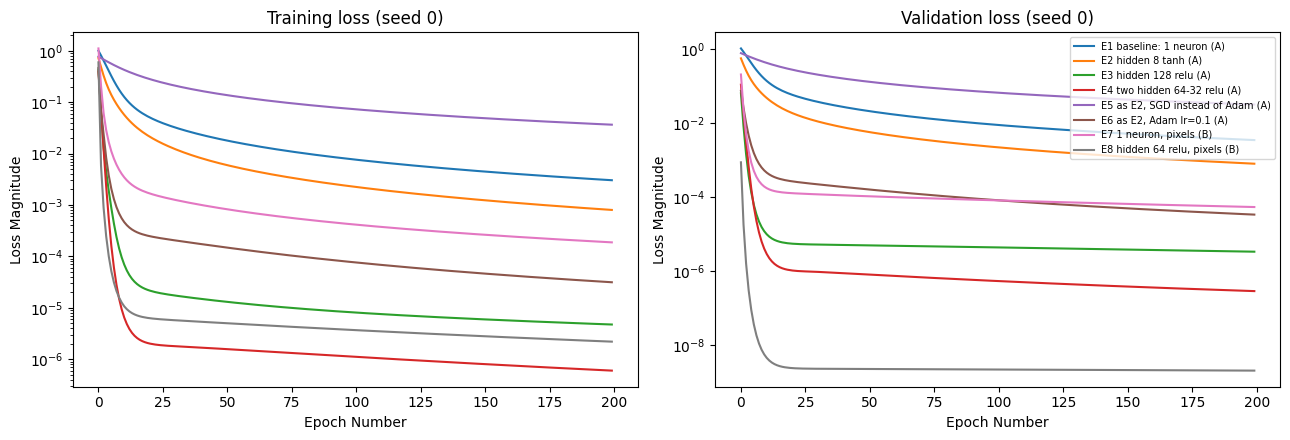

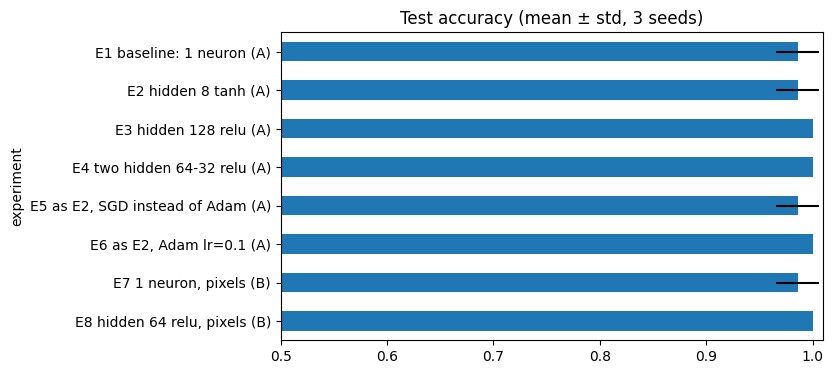

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for r in results:
    axes[0].plot(r['history']['loss'], label=r['experiment'])
    axes[1].plot(r['history']['val_loss'], label=r['experiment'])
axes[0].set_title('Training loss (seed 0)'); axes[1].set_title('Validation loss (seed 0)')
for ax in axes:
    ax.set_xlabel('Epoch Number'); ax.set_ylabel('Loss Magnitude'); ax.set_yscale('log')
axes[1].legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()

table.plot.barh(x='experiment', y='test_acc_mean', xerr='test_acc_std', legend=False,
                figsize=(7, 4), xlim=(0.5, 1.01), title='Test accuracy (mean ± std, 3 seeds)')
plt.gca().invert_yaxis(); plt.show()

### Misclassified test patches (baseline model)

Looking at the errors usually tells more than the accuracy number itself.

Misclassified: 1 of 23


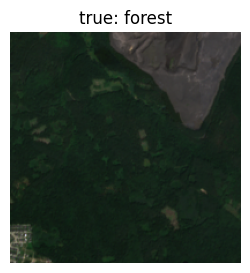

In [26]:
wrong = np.where(y_pred != y_test)[0]
print('Misclassified:', len(wrong), 'of', len(y_test))
if len(wrong):
    fig, axes = plt.subplots(1, min(6, len(wrong)), figsize=(3 * min(6, len(wrong)), 3), squeeze=False)
    for ax, i in zip(axes[0], wrong[:6]):
        ax.imshow(rgb(patches[idx_test[i]]))
        ax.set_title(f"true: {'urban' if y_test[i] else 'forest'}"); ax.axis('off')
    plt.show()

## Test phase: tag of a completely new patch

The trained model is applied to patches from a different city (Warsaw), which were never seen during training.

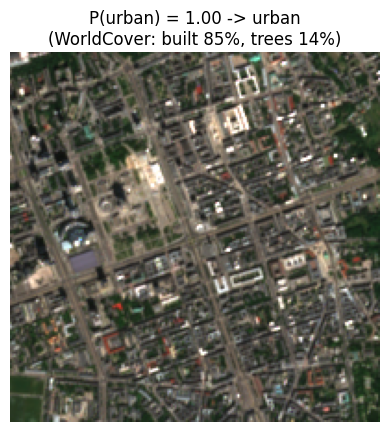

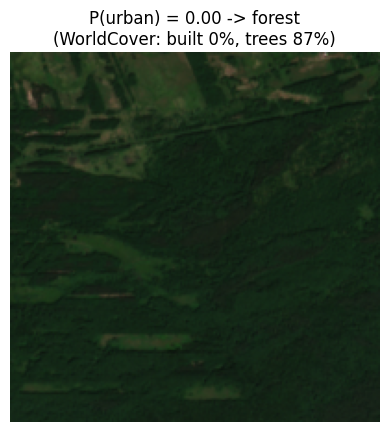

('forest', 0.00013448874233290553)

In [27]:
def classify_location(lon, lat, model=model, scaler=scaler_A):
    zone = int((lon + 180) // 6) + 1
    crs = f'EPSG:326{zone:02d}'
    x, y = Transformer.from_crs('EPSG:4326', crs, always_xy=True).transform(lon, lat)
    spec, built, tree = get_patch(x, y, crs=crs)
    x_new = (features_stats(spec[None].astype(np.uint16)) - scaler[0]) / scaler[1]
    p = float(model.predict(x_new, verbose=False)[0, 0])
    tag = 'urban' if p > 0.5 else 'forest'
    plt.imshow(rgb(spec)); plt.axis('off')
    plt.title(f'P(urban) = {p:.2f} -> {tag}\n(WorldCover: built {built:.0%}, trees {tree:.0%})')
    plt.show()
    return tag, p

classify_location(21.012, 52.230)    # Warsaw city centre
classify_location(20.560, 52.320)    # Kampinos Forest

## Findings

| Exp. | Model | Params | Test acc. (mean ± std, 3 seeds) | Final train loss (seed 0) |
|---|---|---|---|---|
| E1 | 1 neuron, 14 features, Adam 0.01 | 15 | 0.986 ± 0.020 | 0.003 |
| E2 | hidden 8 tanh | 129 | 0.986 ± 0.020 | 0.0008 |
| E3 | hidden 128 relu | 2049 | 1.000 ± 0.000 | ≈ 0 |
| E4 | hidden 64-32 relu | 3073 | 1.000 ± 0.000 | ≈ 0 |
| E5 | as E2, SGD 0.01 | 129 | 0.986 ± 0.020 | 0.036 |
| E6 | as E2, Adam 0.1 | 129 | 1.000 ± 0.000 | ≈ 0 |
| E7 | 1 neuron, 2000 pixels | 2001 | 0.986 ± 0.020 | 0.0002 |
| E8 | hidden 64 relu, 2000 pixels | 128 129 | 1.000 ± 0.000 | ≈ 0 |

Dataset: 112 balanced patches (56 urban, 56 forest), 89 for training (20 % of them used for validation) and 23 for testing.

1. **Baseline (E1).** A single sigmoid neuron with 15 parameters already reaches 95.7 % test accuracy for seed 0 (22/23 patches; one forest patch classified as urban) and 98.6 % on average over three seeds. The training and validation loss curves overlap and converge after about 100 epochs, so there is no overfitting. The weights follow the physics: high mean NIR (B8) and NDVI push towards *forest*, while high SWIR (B11), NDBI and visible reflectance push towards *urban*. The two classes are therefore almost linearly separable in this feature space. Individual weights should not be over-interpreted, because the features are strongly correlated (e.g. NDVI is computed from B8 and B4).
2. **More nodes / more layers (E2–E4).** Larger networks reach 100 % test accuracy and a training loss close to zero, but the gain over the baseline corresponds to at most one test patch in one of three seeds. With 23 test patches one error changes the accuracy by 4.3 percentage points, so the difference is not significant. E3 and E4 have 2049 and 3073 parameters for only 71 training patches, so they could memorise the training set. No overfitting is visible here only because the task is easy.
3. **Optimiser (E2, E5, E6).** SGD with the same learning rate converged much more slowly (final training loss 0.036 vs 0.0008 with Adam) but gave the same test accuracy. Adam with lr = 0.1 converged fastest and did not become unstable for this small, well-scaled problem.
4. **Features (A vs B).** The 2000 downsampled pixel values give the same accuracy as the 14 spectral statistics (98.6–100 %), but need far more parameters (2001–128 129 instead of 15–129). The 14 hand-crafted features describe the problem compactly and are interpretable. The raw-pixel network only works here because urban and forest patches differ already in their average colour.
5. **Stability and time.** The standard deviation between seeds is at most 0.02 (one patch). Every experiment took about 65–74 s for three seeds, regardless of model size, so the training time is dominated by Keras overhead, not by computation.
6. **New patches.** On patches from a different region, the baseline model gave P(urban) = 1.00 for central Warsaw (85 % built-up) and P(urban) = 0.00 for the Kampinos Forest (87 % trees), so it generalises beyond the training area.

**Conclusion.** For a two-class urban/forest problem with good spectral features, the bare-bones single-neuron network is sufficient; extra nodes, layers and a different optimiser change the training speed and the final loss, but not the test accuracy in a meaningful way. The main limitation is the small dataset (112 patches, 23 for testing), so differences of a few percent between the configurations cannot be resolved.